# Classification des prestations

Ce notebook lit le dataset existant, le vérifie, le nettoie et entraîne un modèle pour prédire la prochaine prestation demandée.

## Étape 1 - Charger le dataset

On lit le fichier CSV déjà préparé. Cette étape ne modifie pas le fichier.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data_path = "dataset_prestations.csv"
df = pd.read_csv(data_path)

print("Nombre de lignes :", df.shape[0])
print("Cinq premieres lignes du dataset")
df.head()

Nombre de lignes : 5000
Cinq premieres lignes du dataset


,id_acteur,date_inscription,role,ville,anciennete_mois,historique_atelier_reparation,historique_atelier_couture,historique_formation_bois,historique_formation_materiaux,historique_evenement_decouverte,historique_service_accompagnement,prestation_demandee,reinscription
0,A00001,2026-02-04,Professionnel,Paris,9,10,1,1,1,0,0,Atelier de réparation,1
1,A00002,2021-11-27,Particulier,Ivry-sur-Seine,60,0,1,12,1,3,2,Atelier de couture,1
2,A00003,2023-08-19,Particulier,Paris,39,12,0,0,3,0,2,Atelier de réparation,1
3,A00004,2023-04-21,Professionnel,Paris,43,3,0,2,6,1,0,Formation aux matériaux recyclés,1
4,A00005,2023-07-20,Artisan,Paris,40,3,2,3,2,8,2,Événement découverte de l'upcycling,1


## Étape 2 - Regarder les données

On vérifie le nombre de lignes, les types de colonnes, les valeurs manquantes et les doublons.

In [2]:
print("Nombre de lignes et de colonnes")
print(df.shape)

print("Informations sur les colonnes")
df.info()

print("Valeurs manquantes par colonne")
print(df.isnull().sum())

print("Nombre de lignes en double")
print(df.duplicated().sum())

Nombre de lignes et de colonnes
(5000, 13)
Informations sur les colonnes
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   id_acteur                          5000 non-null   str  
 1   date_inscription                   5000 non-null   str  
 2   role                               5000 non-null   str  
 3   ville                              5000 non-null   str  
 4   anciennete_mois                    5000 non-null   int64
 5   historique_atelier_reparation      5000 non-null   int64
 6   historique_atelier_couture         5000 non-null   int64
 7   historique_formation_bois          5000 non-null   int64
 8   historique_formation_materiaux     5000 non-null   int64
 9   historique_evenement_decouverte    5000 non-null   int64
 10  historique_service_accompagnement  5000 non-null   int64
 11  prestation_demandee 

## Étape 3 - Nettoyer le dataset

On enlève les doublons et les lignes incomplètes. On enlève aussi les espaces inutiles dans les colonnes de texte et on transforme la date en vraie date Python.

In [3]:
print("Taille avant nettoyage")
print(df.shape)

data = df.drop_duplicates()
data = data.dropna()
data = data.copy()

for colonne in ["role", "ville", "prestation_demandee"]:
    data[colonne] = data[colonne].str.strip()

data["date_inscription"] = pd.to_datetime(data["date_inscription"])

print("Taille après nettoyage")
print(data.shape)
data.head()

Taille avant nettoyage
(5000, 13)
Taille après nettoyage
(5000, 13)


,id_acteur,date_inscription,role,ville,anciennete_mois,historique_atelier_reparation,historique_atelier_couture,historique_formation_bois,historique_formation_materiaux,historique_evenement_decouverte,historique_service_accompagnement,prestation_demandee,reinscription
0,A00001,2026-02-04,Professionnel,Paris,9,10,1,1,1,0,0,Atelier de réparation,1
1,A00002,2021-11-27,Particulier,Ivry-sur-Seine,60,0,1,12,1,3,2,Atelier de couture,1
2,A00003,2023-08-19,Particulier,Paris,39,12,0,0,3,0,2,Atelier de réparation,1
3,A00004,2023-04-21,Professionnel,Paris,43,3,0,2,6,1,0,Formation aux matériaux recyclés,1
4,A00005,2023-07-20,Artisan,Paris,40,3,2,3,2,8,2,Événement découverte de l'upcycling,1


## Étape 4 - Vérifier le dataset nettoyé

Le dataset actuel est déjà propre. Ces contrôles montrent que le nettoyage fonctionne aussi si on ajoute plus tard des doublons ou des valeurs manquantes.

In [4]:
print("Valeurs manquantes restantes")
print(data.isnull().sum().sum())

print("Doublons restants")
print(data.duplicated().sum())

print("Nombre de lignes conservées")
print(data.shape[0])

Valeurs manquantes restantes
0
Doublons restants
0
Nombre de lignes conservées
5000


## Étape 5 - Regarder quelques répartitions

Ces graphiques montrent les profils et les prestations présents dans le CSV simulé.

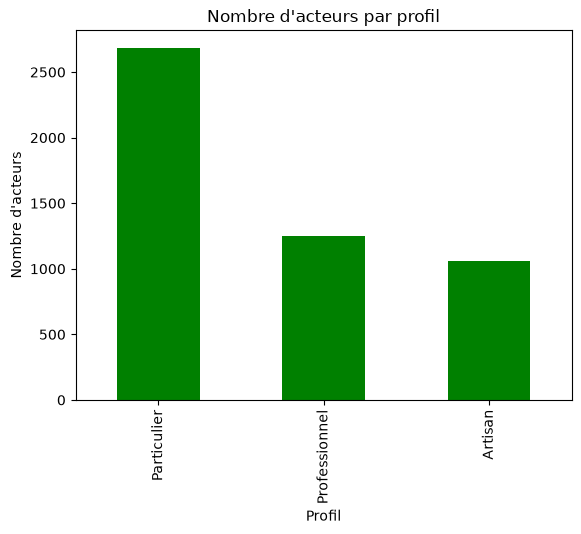

In [5]:
data["role"].value_counts().plot(kind="bar", color="green")
plt.title("Nombre d'acteurs par profil")
plt.xlabel("Profil")
plt.ylabel("Nombre d'acteurs")
plt.show()

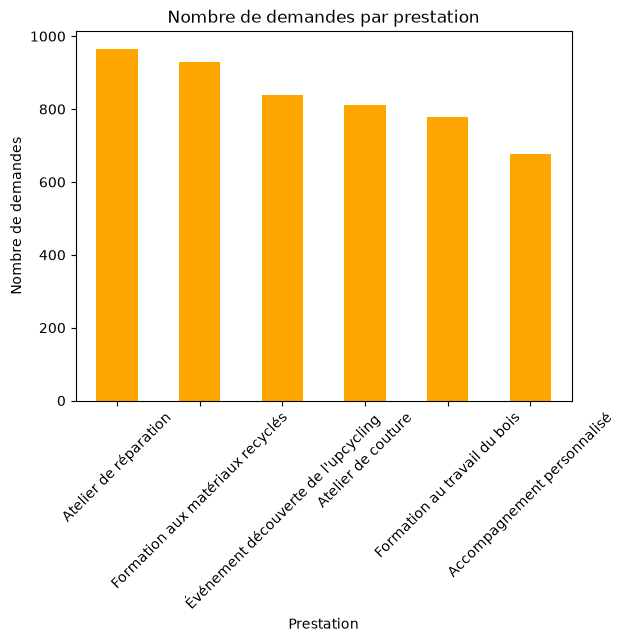

In [6]:
data["prestation_demandee"].value_counts().plot(kind="bar", color="orange")
plt.title("Nombre de demandes par prestation")
plt.xlabel("Prestation")
plt.ylabel("Nombre de demandes")
plt.xticks(rotation=45)
plt.show()

## Étape 6 - Préparer les données pour le modèle

La colonne à prédire est prestation_demandee. On garde le rôle, l’ancienneté et l’historique, qui sont connus avant la prochaine demande. La ville est conservée dans le CSV, mais elle ne participe pas à la simulation de la prestation.

In [7]:
colonnes_entree = [
    "role",
    "anciennete_mois",
    "historique_atelier_reparation",
    "historique_atelier_couture",
    "historique_formation_bois",
    "historique_formation_materiaux",
    "historique_evenement_decouverte",
    "historique_service_accompagnement",
]

X = data[colonnes_entree]
y = data["prestation_demandee"]

print("Informations donnees au modele")
X.head()

Informations donnees au modele


,role,anciennete_mois,historique_atelier_reparation,historique_atelier_couture,historique_formation_bois,historique_formation_materiaux,historique_evenement_decouverte,historique_service_accompagnement
0,Professionnel,9,10,1,1,1,0,0
1,Particulier,60,0,1,12,1,3,2
2,Particulier,39,12,0,0,3,0,2
3,Professionnel,43,3,0,2,6,1,0
4,Artisan,40,3,2,3,2,8,2


## Étape 7 - Séparer les données

On garde 80 % des lignes pour apprendre et 20 % pour vérifier le modèle. Le même partage est utilisé à chaque lancement.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

colonnes_categorielles = ["role"]

preparation = ColumnTransformer(
    transformers=[
        ("categories", OneHotEncoder(handle_unknown="ignore"), colonnes_categorielles)
    ],
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

print("Lignes pour apprendre :", X_train.shape[0])
print("Lignes pour verifier :", X_test.shape[0])

Lignes pour apprendre : 4000
Lignes pour verifier : 1000


## Étape 8 - Créer le modèle

On affiche d’abord le score d’une règle de base qui choisit toujours la prestation la plus fréquente. Ensuite, on entraîne un arbre de décision peu profond pour comparer.

In [9]:
modele_base = DummyClassifier(strategy="most_frequent")
modele_base.fit(X_train, y_train)
predictions_base = modele_base.predict(X_test)
print("Exactitude de base :", accuracy_score(y_test, predictions_base))

modele = Pipeline(
    steps=[
        ("preparation", preparation),
        ("classification", DecisionTreeClassifier(max_depth=5, random_state=1))
    ]
)

modele.fit(X_train, y_train)
print("Le modele a termine son apprentissage.")

Exactitude de base : 0.193
Le modele a termine son apprentissage.


## Étape 9 - Vérifier les prédictions

On compare les prestations prédites aux vraies réponses de la partie test. L’exactitude indique la part de réponses correctes.

Exactitude : 0.791
                                     precision    recall  f1-score   support

        Accompagnement personnalisé       0.77      0.71      0.74       135
                 Atelier de couture       0.78      0.77      0.77       162
              Atelier de réparation       0.78      0.81      0.80       193
       Formation au travail du bois       0.79      0.81      0.80       156
   Formation aux matériaux recyclés       0.80      0.83      0.81       186
Événement découverte de l'upcycling       0.82      0.80      0.81       168

                           accuracy                           0.79      1000
                          macro avg       0.79      0.79      0.79      1000
                       weighted avg       0.79      0.79      0.79      1000



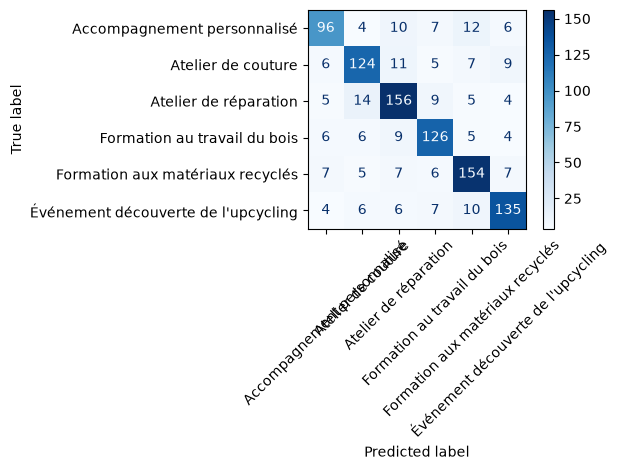

In [10]:
predictions = modele.predict(X_test)

print("Exactitude :", accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, xticks_rotation=45, cmap="Blues"
)
plt.tight_layout()
plt.show()

## Étape 10 - Tester un nouveau profil

On donne au modèle un exemple de profil avec son historique. Il propose une prestation parmi celles du dataset.

In [11]:
nouvel_acteur = pd.DataFrame([{
    "role": "Particulier",
    "anciennete_mois": 18,
    "historique_atelier_reparation": 8,
    "historique_atelier_couture": 1,
    "historique_formation_bois": 0,
    "historique_formation_materiaux": 1,
    "historique_evenement_decouverte": 2,
    "historique_service_accompagnement": 0
}])

prestation_proposee = modele.predict(nouvel_acteur)
print("Prestation proposee :", prestation_proposee[0])

Prestation proposee : Atelier de réparation
